# Learning from averages

Suppose a sensor reports the average of a function over a window. A nearly
flat function and one that rises and falls can give the same reading.
How much can we learn about what happens inside the window?

We'll use three window averages to predict the function, then compare our
uncertainty about individual values with our uncertainty about the averages.
Then we will use the same observations to predict an accumulated integral.

In [1]:
import jax

jax.config.update("jax_enable_x64", True)

import jax.numpy as jnp

from gpex import (
    FunctionalBlock, FunctionalDataset, FunctionalQuery,
    GaussianProcess, ObservationBlock, kernels, operators,
)

In [2]:
import matplotlib.pyplot as plt

plt.rcParams.update({
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.18,
    "font.size": 10,
})
BLUE, ORANGE = "#1F4E79", "#D97706"


def plot_prediction(ax, locations, prediction, name):
    mean = prediction.mean[name]
    sd = jnp.sqrt(prediction.variance[name])
    ax.plot(locations[:, 0], mean, color=BLUE, lw=2, zorder=3, label="Posterior mean")
    ax.fill_between(
        locations[:, 0], mean - 1.96 * sd, mean + 1.96 * sd,
        color=BLUE, alpha=0.12, zorder=0, label="95% posterior interval",
    )


def plot_draws(ax, locations, draws, name):
    ax.plot(
        locations[:, 0], draws[name].T,
        color=BLUE, lw=0.8, alpha=0.3, zorder=1,
    )

## Measure three window averages

`BoxAverage(radius=0.55)` measures the mean over an interval of width `1.1`.
The locations below are the window centers. For example, the first window
covers `[-1.65, -0.55]`. `quadrature_order=24` uses 24 evaluation points to
approximate each average.

Use a known function to generate synthetic averages, then add independent
Gaussian measurement errors with standard deviation `0.04`.

In [3]:
def truth(point):
    x = point[0]
    return 0.4 + jnp.sin(2.4 * x) + 0.3 * jnp.cos(5.0 * x)


centers = jnp.array([[-1.1], [-0.05], [1.1]])
average = operators.BoxAverage(radius=0.55, quadrature_order=24)
y_average = jax.vmap(lambda point: average.apply(truth, point))(centers)
y_average += 0.04 * jax.random.normal(jax.random.key(5), (3,))

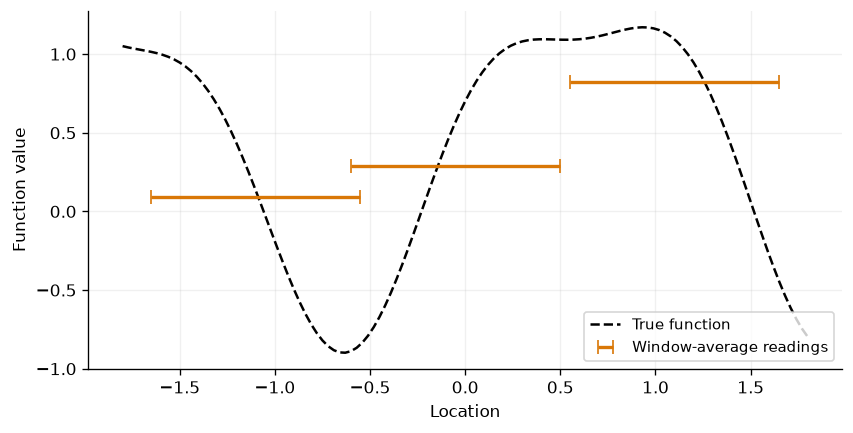

In [4]:
x_plot = jnp.linspace(-1.8, 1.8, 121)[:, None]
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
ax.plot(x_plot[:, 0], jax.vmap(truth)(x_plot), "k--", label="True function")
ax.errorbar(
    centers[:, 0], y_average, xerr=0.55, fmt="none",
    ecolor=ORANGE, elinewidth=2, capsize=4, label="Window-average readings",
)
ax.set(xlabel="Location", ylabel="Function value")
ax.legend(fontsize=9)
plt.show()

Each orange segment spans a sensor window at the height of its measured
average. The function rises above and falls below that height within the
window. The reading does not tell us the function value at the center.

## Predict the function and its averages

Put `average` in the observation block to tell gpex what the sensor measures.
The prior's lengthscale of `0.35` allows variation within each window.

In [5]:
average_block = ObservationBlock.from_arrays(
    centers, y_average, operator=average,
    variance=0.04**2, name="averages", max_size=3,
)
gp = GaussianProcess(kernels.RBFKernel(variance=1.0, lengthscale=0.35))
posterior = gp.condition(FunctionalDataset([average_block]))

Use `Identity()` in a query for individual function values. Use `average`
to ask for the average over a window centered at each query location.
We can request both in the same query.

In [6]:
query = FunctionalQuery([
    FunctionalBlock(x_plot, operators.Identity(), name="function"),
    FunctionalBlock(x_plot, average, name="average"),
])
prediction = posterior.predict_marginals(query)
draws = posterior.sample(jax.random.key(6), query, sample_count=10)

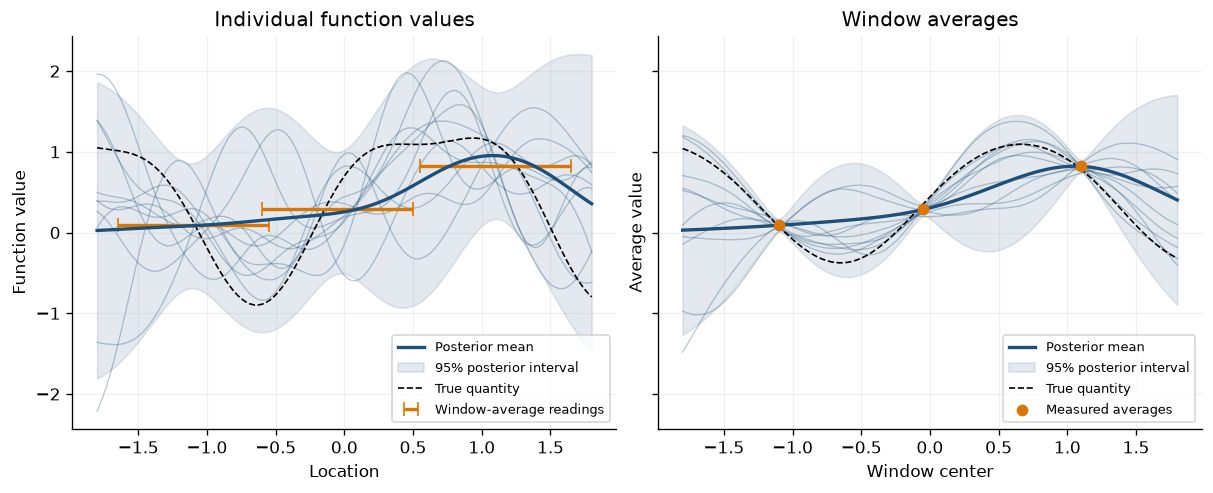

In [7]:
fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained"
)
for ax, operator, name, title in [
    (axes[0], operators.Identity(), "function", "Individual function values"),
    (axes[1], average, "average", "Window averages"),
]:
    plot_draws(ax, x_plot, draws, name)
    plot_prediction(ax, x_plot, prediction, name)
    reference = jax.vmap(lambda point: operator.apply(truth, point))(x_plot)
    ax.plot(x_plot[:, 0], reference, "k--", lw=1, label="True quantity")
    ax.set(title=title)

axes[0].errorbar(
    centers[:, 0], y_average, xerr=0.55, fmt="none",
    ecolor=ORANGE, elinewidth=2, capsize=4, label="Window-average readings",
)
axes[1].scatter(
    centers[:, 0], y_average, color=ORANGE, zorder=4, label="Measured averages"
)
axes[0].set(xlabel="Location", ylabel="Function value")
axes[1].set(xlabel="Window center", ylabel="Average value")
for ax in axes:
    ax.legend(fontsize=8, loc="lower right")
plt.show()

The faint lines show ten posterior draws.
The blue bands show pointwise 95% posterior intervals. At the observed centers,
the window averages are tightly constrained. Individual function values remain
much less certain: rises and falls inside a window can cancel in its average.
The prior determines how much of this variation we expect.

To learn more about that local variation, collect averages over smaller windows
or measure individual function values.

## Predict an accumulated integral

Suppose we also want the total accumulated from the left edge of the first
window to each location:

$$
I(x) = \int_{-1.65}^{x} f(t)\,\mathrm{d}t.
$$

Use `CumulativeIntegral1D(base=-1.65)` in a new query. The observations remain
the same three window averages.

In [8]:
x_total = jnp.linspace(-1.65, 1.65, 111)[:, None]
total = operators.CumulativeIntegral1D(base=-1.65, quadrature_order=32)
integral_query = FunctionalQuery([
    FunctionalBlock(x_total, total, name="total")
])
integral_prediction = posterior.predict_marginals(integral_query)
integral_draws = posterior.sample(jax.random.key(7), integral_query, sample_count=10)

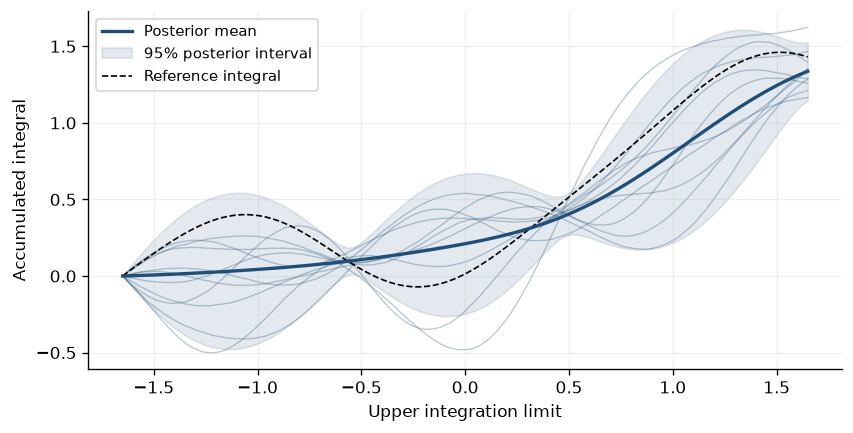

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
plot_draws(ax, x_total, integral_draws, "total")
plot_prediction(ax, x_total, integral_prediction, "total")
reference = jax.vmap(lambda point: total.apply(truth, point))(x_total)
ax.plot(x_total[:, 0], reference, "k--", lw=1, label="Reference integral")
ax.set(xlabel="Upper integration limit", ylabel="Accumulated integral")
ax.legend(fontsize=9)
plt.show()

The integral is zero at its starting point. Beyond that, the average
measurements constrain the areas over their windows, providing information
about the accumulated total even while individual function values remain
uncertain.

When changing window sizes or the kernel lengthscale, compare predictions with
a higher `quadrature_order` to check the integration accuracy. More evaluation
points increase the computational cost.